# BÁO CÁO PHỤ TRÁCH: II.4. KẾT QUẢ THỰC NGHIỆM, PHÂN TÍCH KẾT QUẢ & SỐ LIỆU CHO PHẦN III
**Công cụ thực hiện:** Google Colab, Scikit-learn, Matplotlib, Excel, Word.

**Quy trình 9 bước thực hiện:**
1. Nhận `y_test` / `y_pred` từ Toàn (`y_test_y_pred_v2.csv`).
2. Tính Accuracy, Precision, Recall, F1 (ghi rõ phương pháp `average`: `macro`, `weighted`, `micro`).
3. Tạo Confusion Matrix.
4. Kiểm tra tổng số mẫu trong ma trận khớp tập Test (`1.160` mẫu).
5. Đọc số dự đoán Đúng / Sai theo từng lớp (`ham`, `spam`, `smishing`).
6. Trích xuất và chọn các mẫu dự đoán sai tiêu biểu.
7. Phân tích nguyên nhân (từ ngữ mơ hồ, viết tắt, dữ liệu nhiễu, mất cân bằng, giới hạn mô hình).
8. Nêu hạn chế và hướng cải tiến.
9. Tổng hợp số liệu cung cấp cho Phần III và viết Kết luận.

In [1]:
# BƯỚC 1, 2, 3, 4, 5: ĐỌC DỮ LIỆU, TÍNH CHỈ SỐ ĐÁNH GIÁ, TẠO CONFUSION MATRIX & KIỂM TRA SỐ MẪU
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

df = pd.read_csv('y_test_y_pred_v2.csv')
y_test = df['y_test']
y_pred = df['y_pred']
labels = ['ham', 'spam', 'smishing']

# Tính Accuracy và Precision, Recall, F1 với các phương pháp average
acc = accuracy_score(y_test, y_pred)
p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(y_test, y_pred, labels=labels, average='macro')
p_wei, r_wei, f1_wei, _ = precision_recall_fscore_support(y_test, y_pred, labels=labels, average='weighted')
p_mic, r_mic, f1_mic, _ = precision_recall_fscore_support(y_test, y_pred, labels=labels, average='micro')

summary_df = pd.DataFrame([
    {'Chỉ số': 'Accuracy', 'Average': 'Toàn tập Test (N=1160)', 'Giá trị': round(acc, 4), 'Tỷ lệ (%)': f'{acc*100:.2f}%'},
    {'Chỉ số': 'Precision', 'Average': 'macro', 'Giá trị': round(p_mac, 4), 'Tỷ lệ (%)': f'{p_mac*100:.2f}%'},
    {'Chỉ số': 'Recall', 'Average': 'macro', 'Giá trị': round(r_mac, 4), 'Tỷ lệ (%)': f'{r_mac*100:.2f}%'},
    {'Chỉ số': 'F1-score', 'Average': 'macro', 'Giá trị': round(f1_mac, 4), 'Tỷ lệ (%)': f'{f1_mac*100:.2f}%'},
    {'Chỉ số': 'Precision', 'Average': 'weighted', 'Giá trị': round(p_wei, 4), 'Tỷ lệ (%)': f'{p_wei*100:.2f}%'},
    {'Chỉ số': 'Recall', 'Average': 'weighted', 'Giá trị': round(r_wei, 4), 'Tỷ lệ (%)': f'{r_wei*100:.2f}%'},
    {'Chỉ số': 'F1-score', 'Average': 'weighted', 'Giá trị': round(f1_wei, 4), 'Tỷ lệ (%)': f'{f1_wei*100:.2f}%'},
    {'Chỉ số': 'Precision/Recall/F1', 'Average': 'micro', 'Giá trị': round(f1_mic, 4), 'Tỷ lệ (%)': f'{f1_mic*100:.2f}%'},
])
print('=== 1. BẢNG ACCURACY, PRECISION, RECALL, F1 ===')
print(summary_df.to_string(index=False))

print('\n=== 2. CLASSIFICATION REPORT ===')
print(classification_report(y_test, y_pred, labels=labels, digits=4))

cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f'Thực tế: {l}' for l in labels], columns=[f'Dự đoán: {l}' for l in labels])
print('=== 3. CONFUSION MATRIX ===')
print(cm_df)
print(f'\n=== 4. KIỂM TRA TỔNG MẪU: Tổng ma trận = {cm.sum()} | Kích thước tập Test = {len(df)} | Khớp: {cm.sum() == len(df)} ===')


=== 1. BẢNG ACCURACY, PRECISION, RECALL, F1 ===
             Chỉ số                Average  Giá trị Tỷ lệ (%)
           Accuracy Toàn tập Test (N=1160)   0.9621    96.21%
          Precision                  macro   0.8860    88.60%
             Recall                  macro   0.8913    89.13%
           F1-score                  macro   0.8886    88.86%
          Precision               weighted   0.9624    96.24%
             Recall               weighted   0.9621    96.21%
           F1-score               weighted   0.9622    96.22%
Precision/Recall/F1                  micro   0.9621    96.21%

=== 2. CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         ham     0.9865    0.9845    0.9855       967
        spam     0.7753    0.7931    0.7841        87
    smishing     0.8962    0.8962    0.8962       106

    accuracy                         0.9621      1160
   macro avg     0.8860    0.8913    0.8886      1160
weighted avg     0.9624    0.9621 

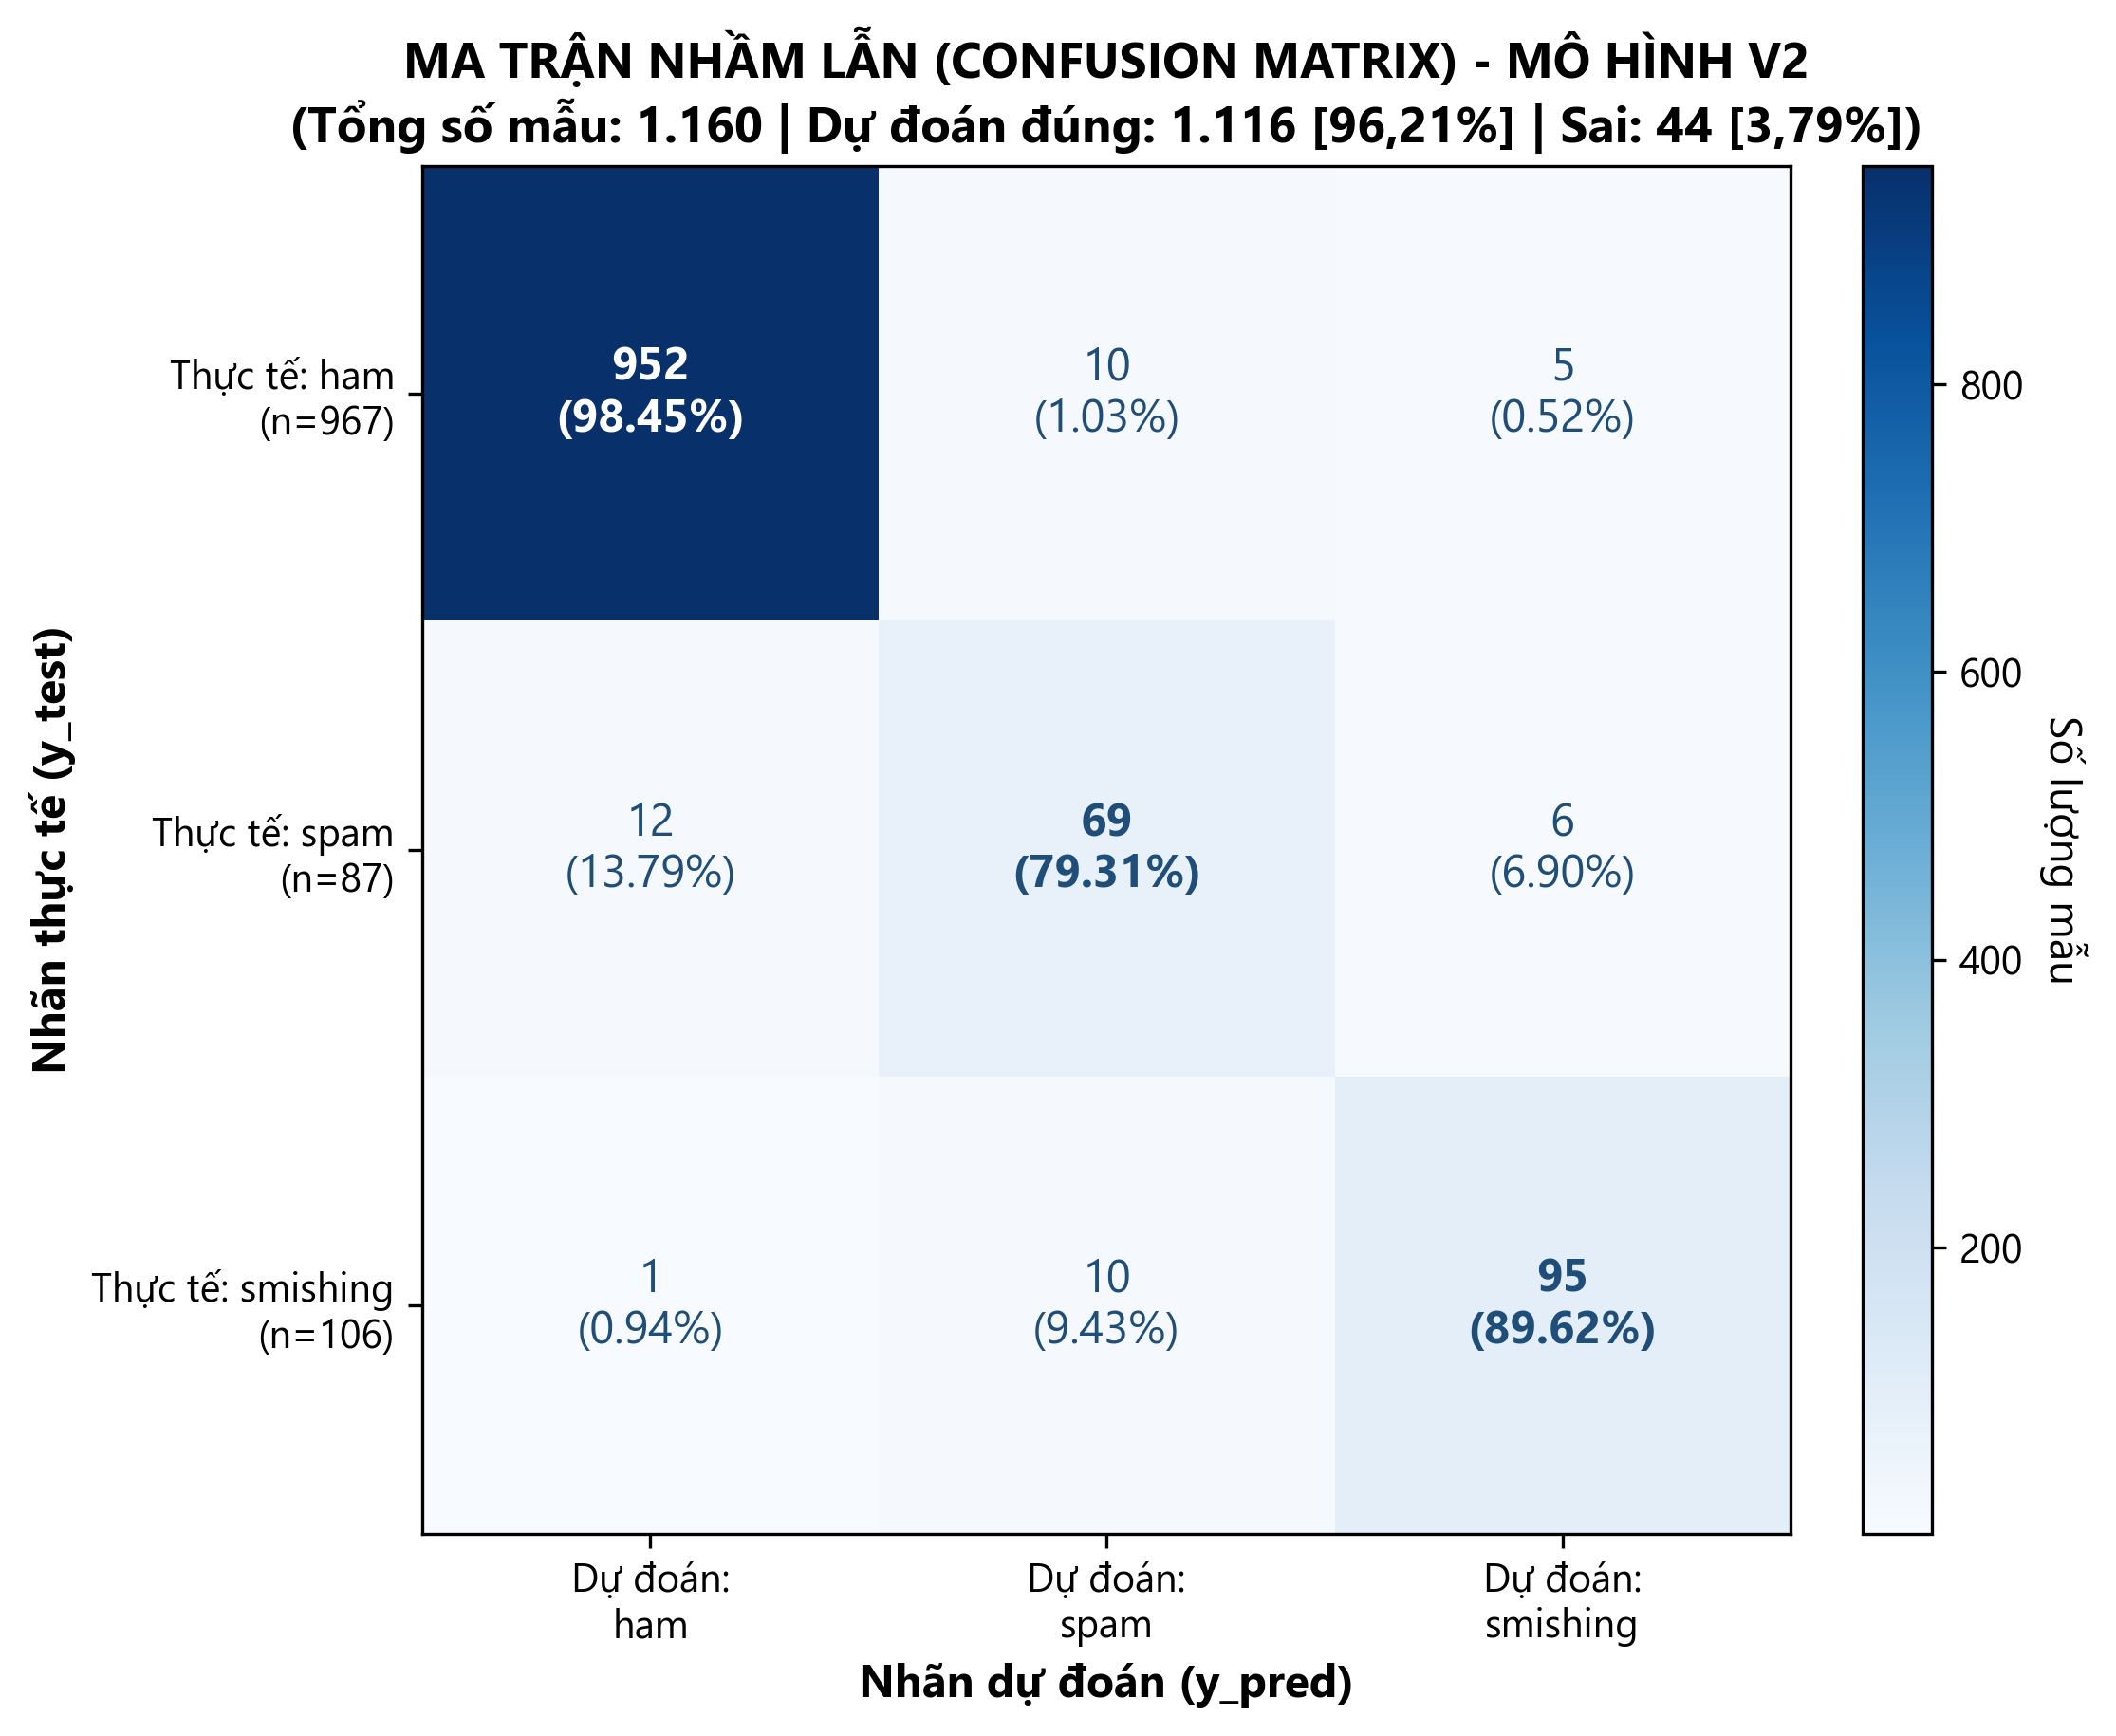

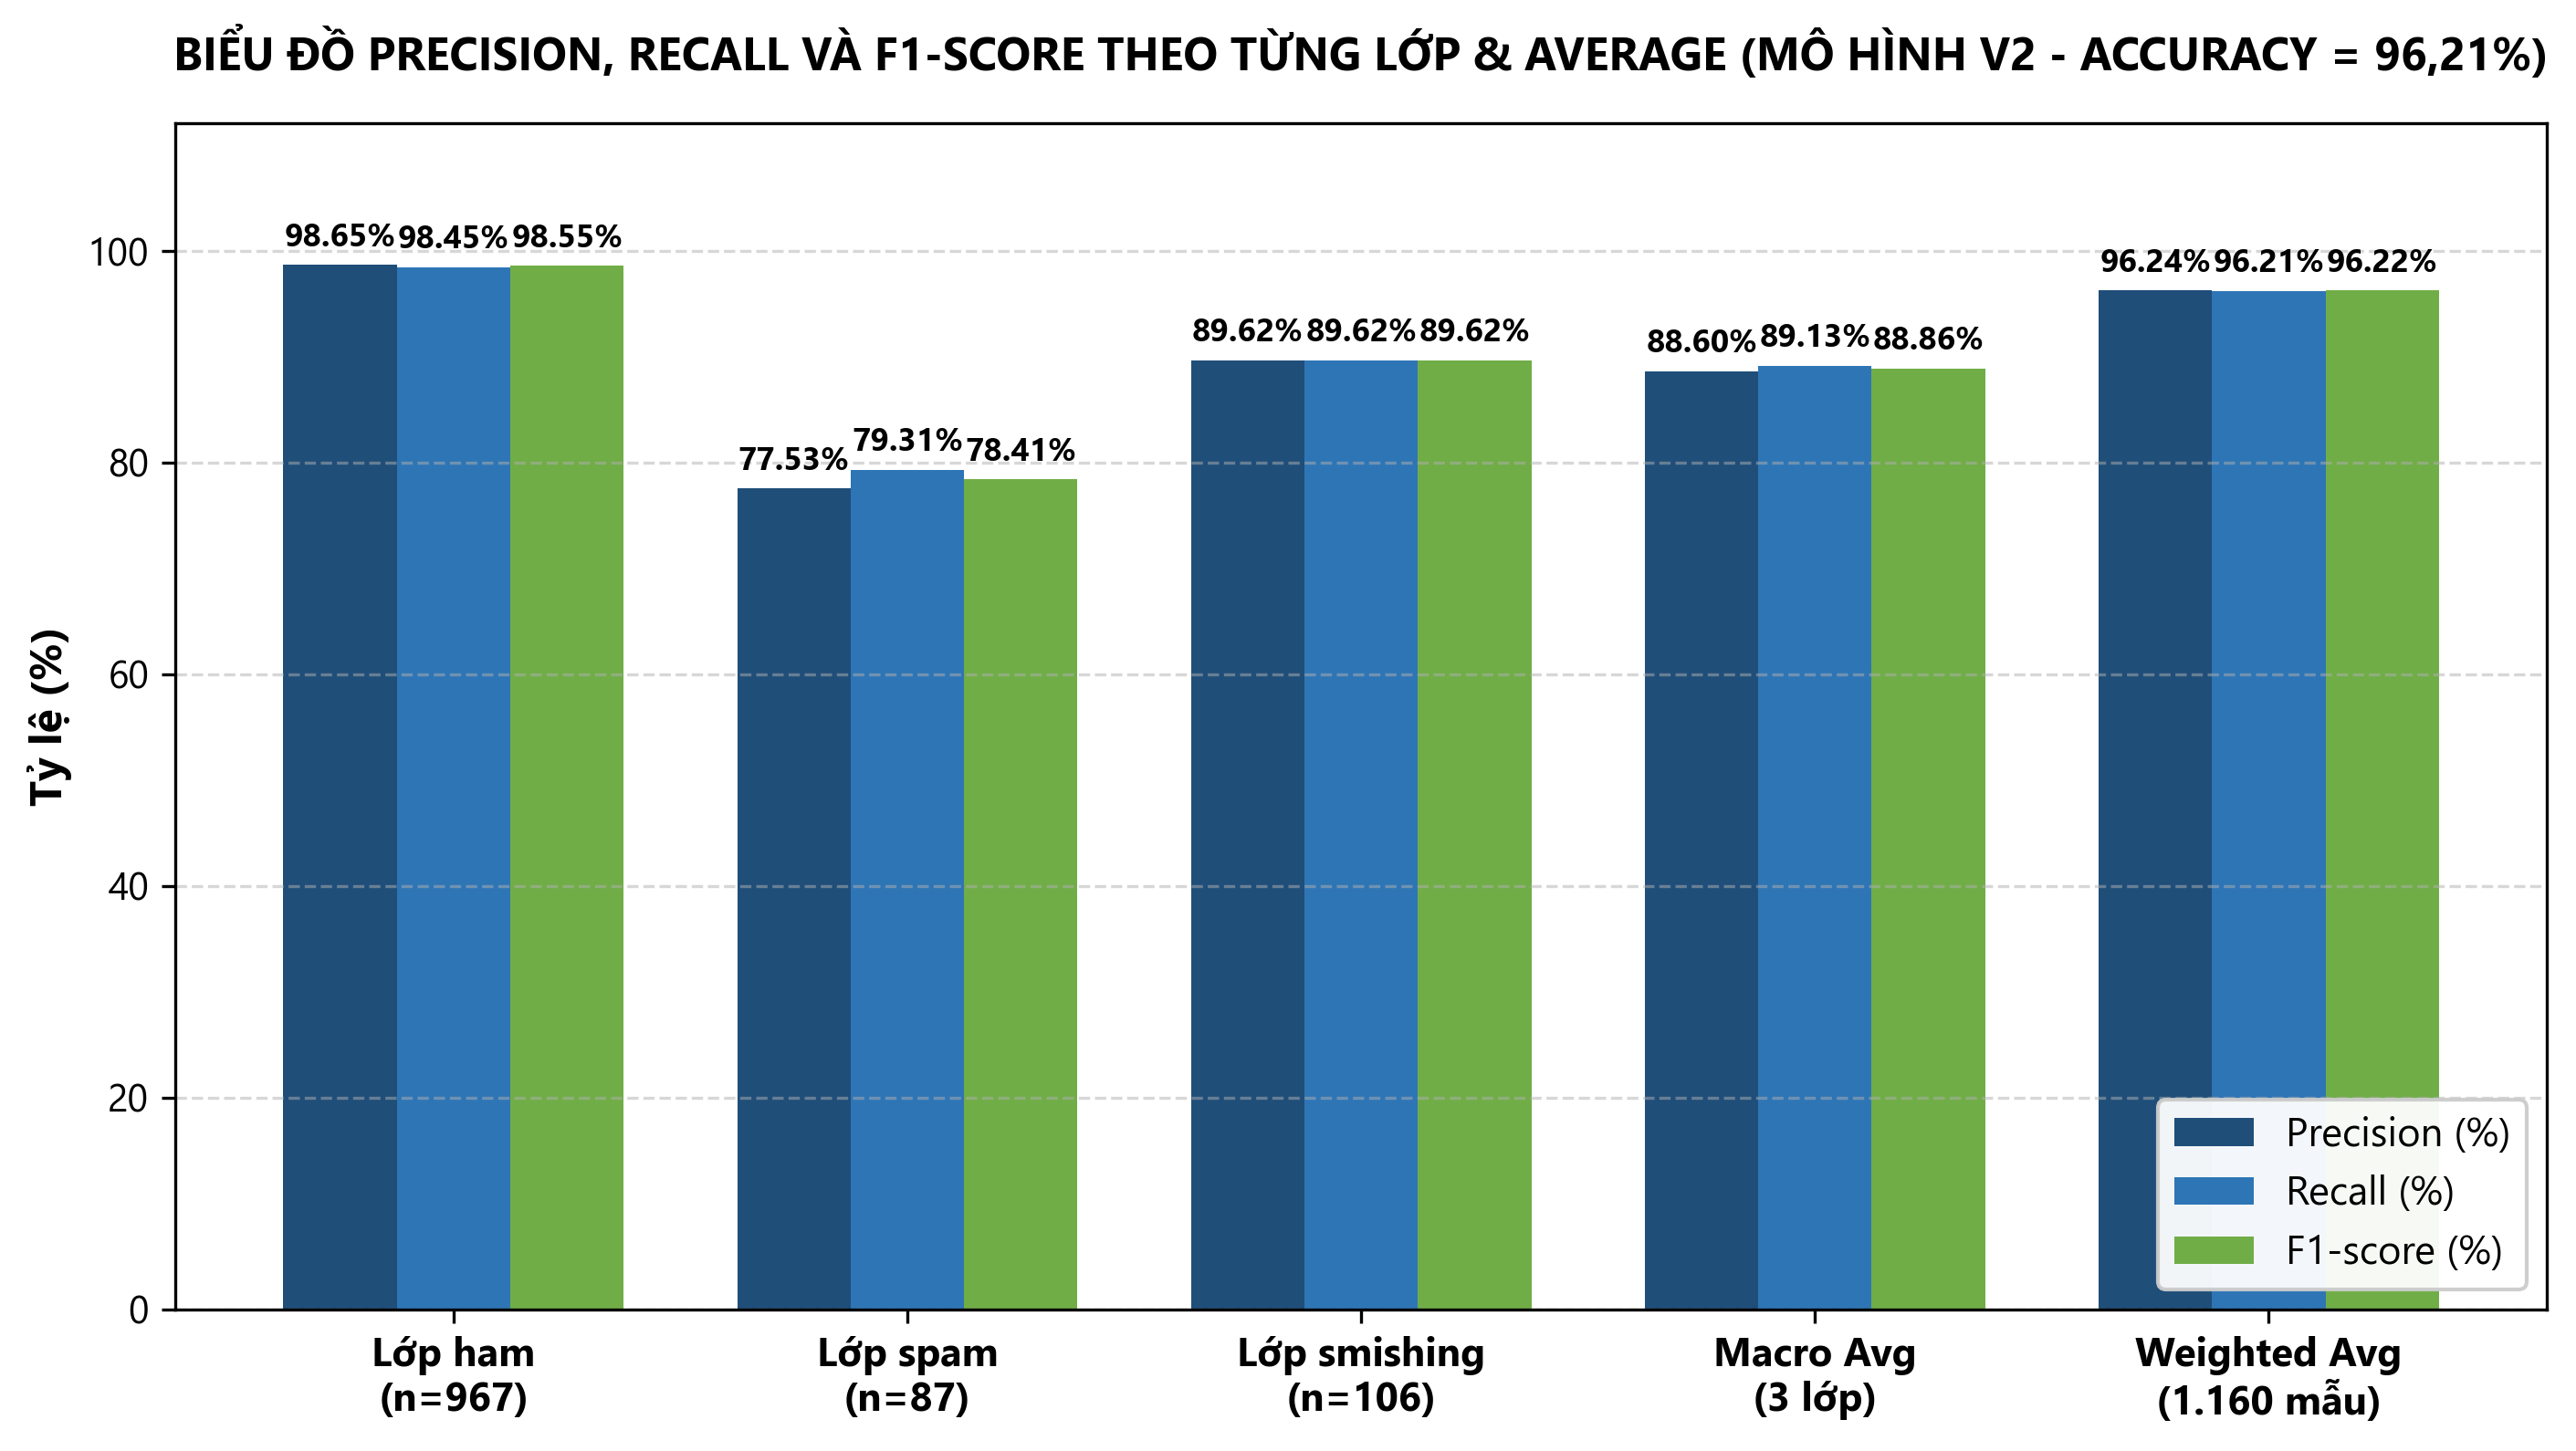

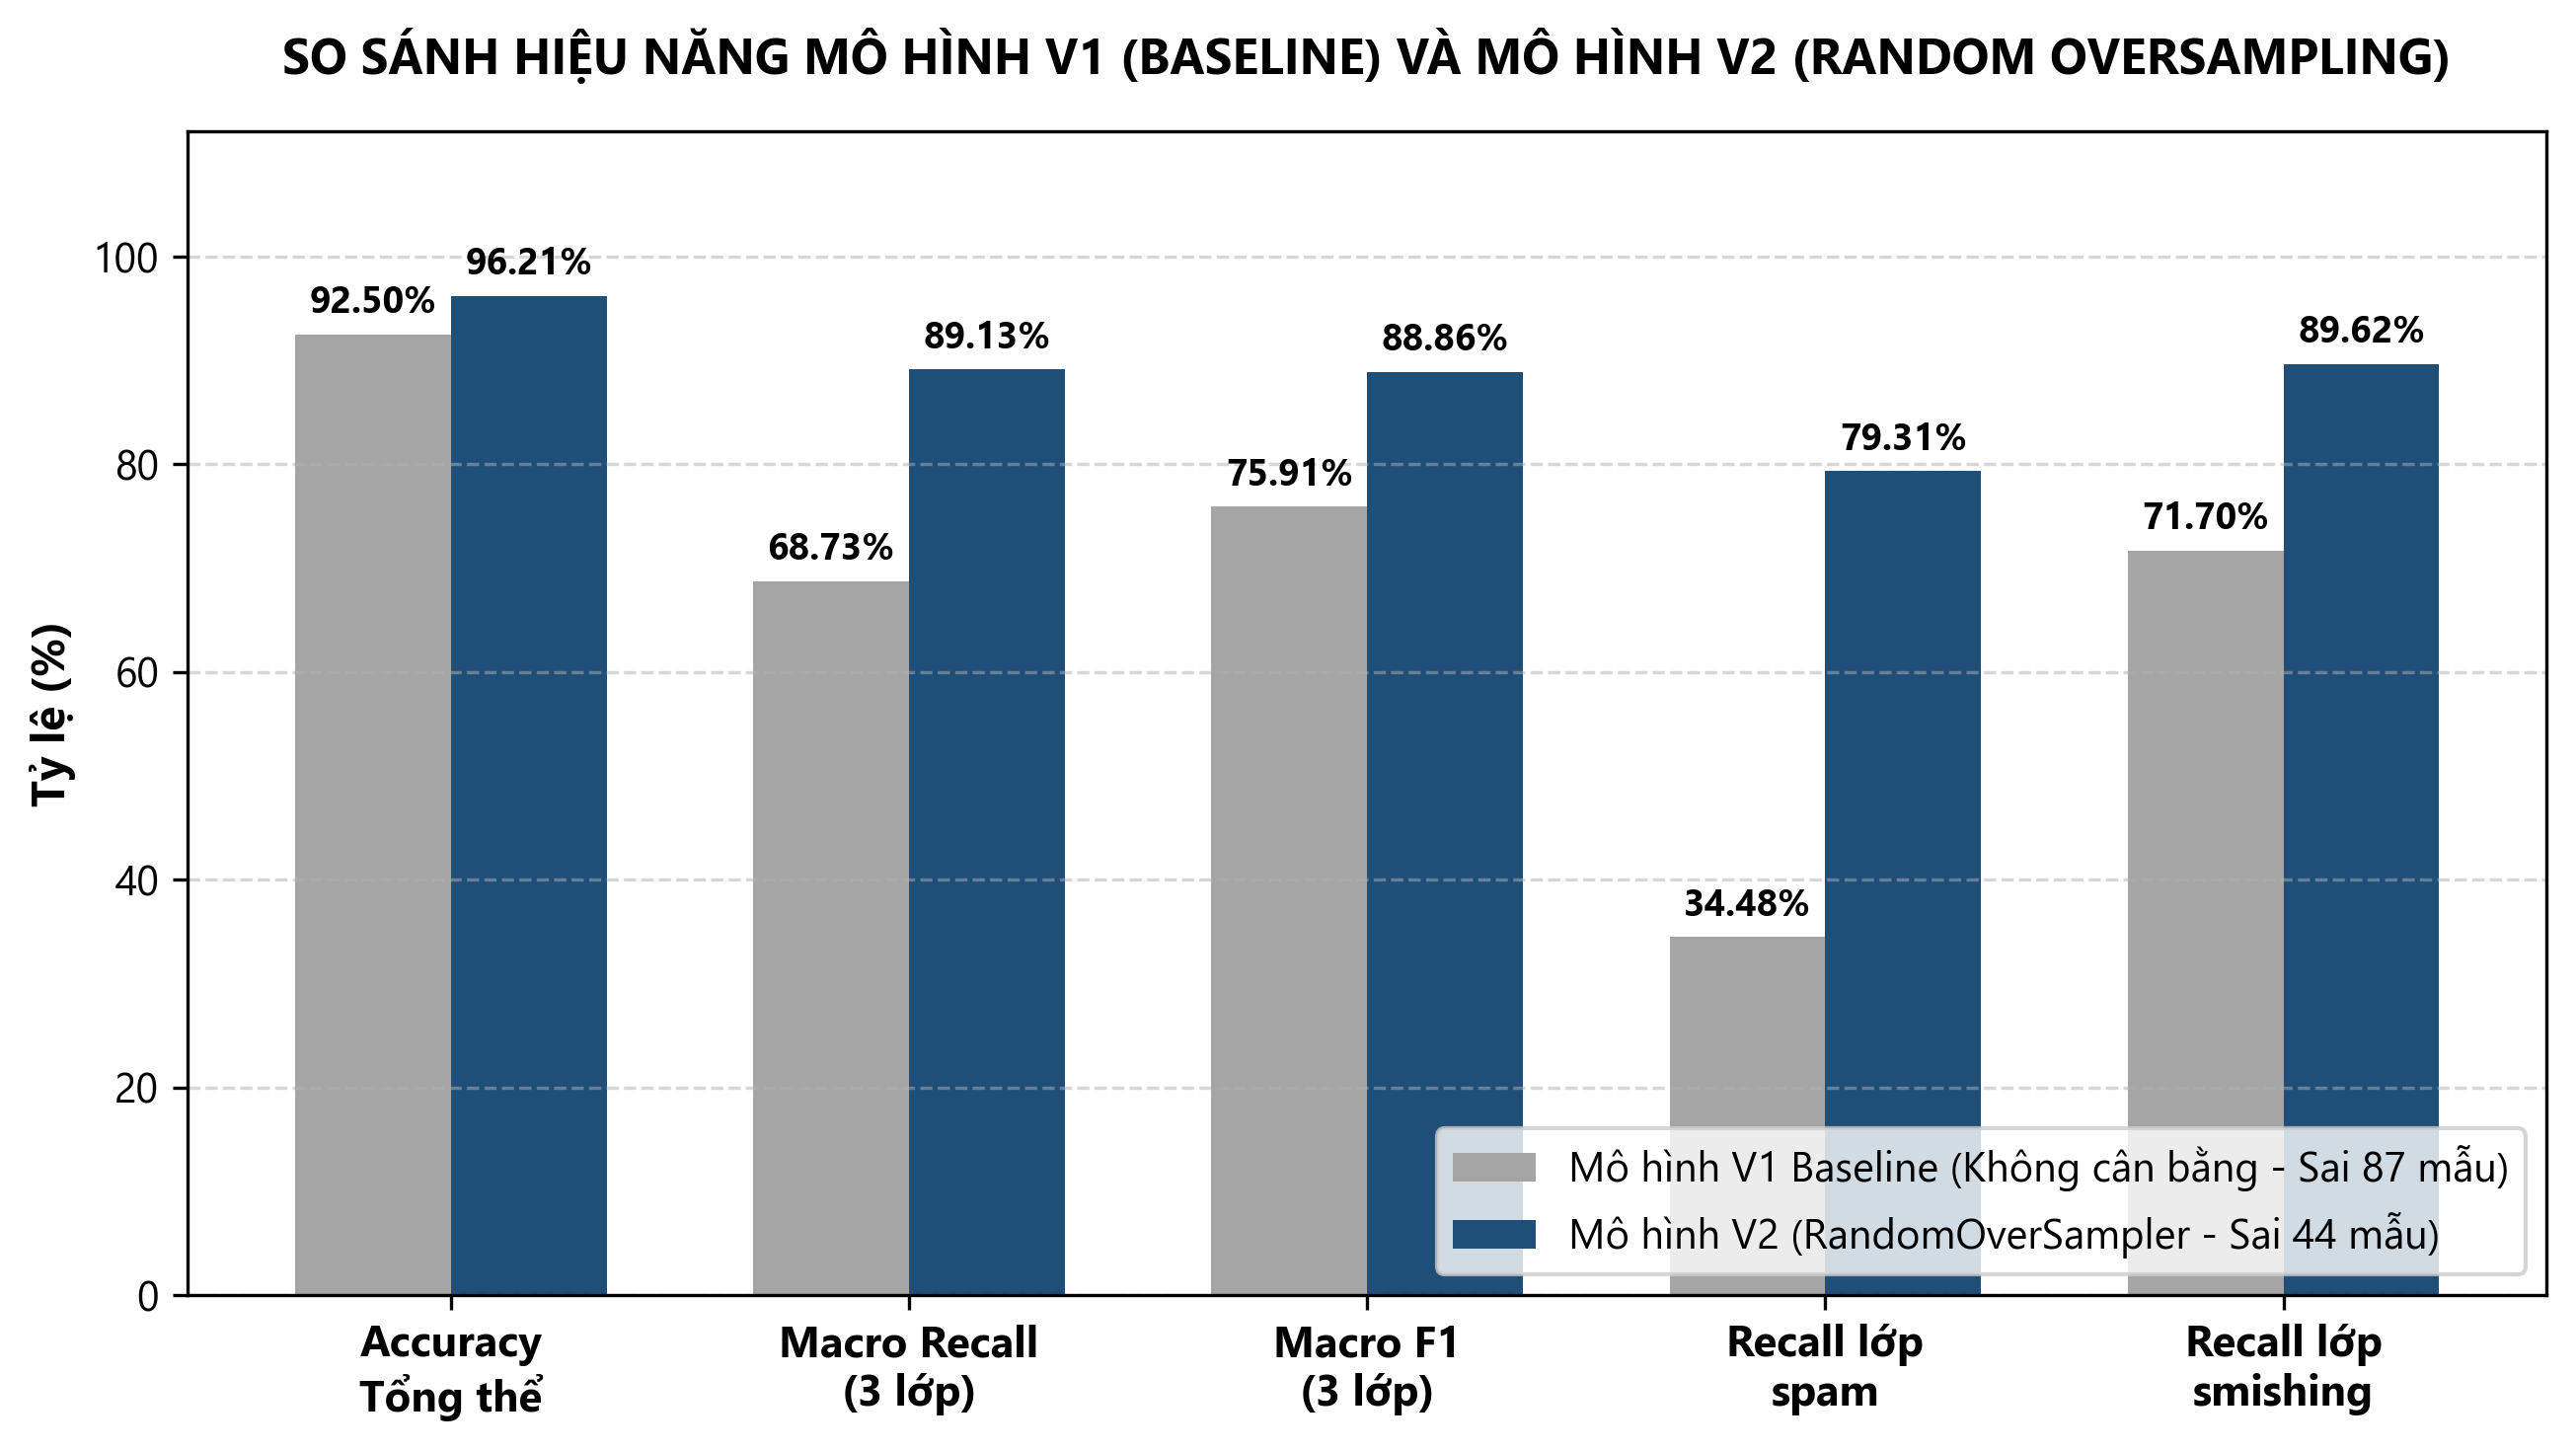

In [2]:
# VẼ BIỂU ĐỒ CONFUSION MATRIX & BIỂU ĐỒ CHỈ SỐ BẰNG MATPLOTLIB
import matplotlib.pyplot as plt
# Hiển thị biểu đồ Confusion Matrix và Biểu đồ Precision - Recall - F1
